In [1]:
import os
import cv2
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

In [2]:
# --- 1. CONFIGURATION ---
IMG1_PATH = '../data/raw/test_fullsized_images/IAS_27288_Rotation1_300dpi.png'
IMG2_PATH = '../data/raw/test_fullsized_images/IAS_27288_Rotation2_300dpi.png'

YOLO_MODEL_PATH = '../runs/obb/train3/weights/best.pt'
CLS_MODEL_PATH = '../models/greek_classifier_resnet18_20260214_212940.pth' # Update timestamp if needed
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate the class names list EXACTLY as trained
TRAIN_DIR = '../data/processed/greek_letters_classification/train'
CLASS_NAMES = sorted([d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))])
print(f"Loaded {len(CLASS_NAMES)} classes.")

Loaded 27 classes.


In [3]:
# --- 2. LOAD YOLO (Via SAHI for large images) ---
detection_model = AutoDetectionModel.from_pretrained(
    model_type='yolov8', # 'yolov8' works for v11 in SAHI framework
    model_path=YOLO_MODEL_PATH,
    confidence_threshold=0.25,
    device=DEVICE,
)

In [4]:
# --- 3. LOAD RESNET CLASSIFIER ---
classifier = models.resnet18(weights=None)
classifier.fc = nn.Linear(classifier.fc.in_features, len(CLASS_NAMES))
classifier.load_state_dict(torch.load(CLS_MODEL_PATH, map_location='cpu')) # CPU load
classifier.to(DEVICE)
classifier.eval()

cls_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
print("Models loaded successfully.")

/tmp/ipykernel_458192/3343530219.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  classifier.load_state_dict(torch.load(CLS_MODEL_PATH, map_location='cpu')) # CPU load


Models loaded successfully.


In [27]:
# import math

# # --- 1. RUN YOLO ON BOTH IMAGES SEPARATELY ---
# print("Running Detection on Image 1...")
# res1 = get_sliced_prediction(IMG1_PATH, detection_model, slice_height=640, slice_width=640, overlap_height_ratio=0.2, overlap_width_ratio=0.2, postprocess_type="NMS")
# boxes1 = res1.object_prediction_list

# print("Running Detection on Image 2...")
# res2 = get_sliced_prediction(IMG2_PATH, detection_model, slice_height=640, slice_width=640, overlap_height_ratio=0.2, overlap_width_ratio=0.2, postprocess_type="NMS")
# boxes2 = res2.object_prediction_list

# # Load raw images
# img1_cv2 = cv2.imread(IMG1_PATH)
# img2_cv2 = cv2.imread(IMG2_PATH)
# h1, w1, _ = img1_cv2.shape
# h2, w2, _ = img2_cv2.shape

# final_results = []
# PROXIMITY_THRESHOLD = 50 # Max pixels they can be apart to be considered the same letter

# print("-" * 50)
# print("Running Proximity Matching & Classification Tournament...")

# conflict_count = 0

# # --- 2. MATCH AND COMPETE ---
# for b1 in boxes1:
#     # Get center of Box 1
#     x1_min, y1_min, x1_max, y1_max = map(int, b1.bbox.to_xyxy())
#     cx1, cy1 = (x1_min + x1_max) / 2, (y1_min + y1_max) / 2
    
#     # Find the closest box in Image 2
#     closest_b2 = None
#     min_dist = float('inf')
    
#     for b2 in boxes2:
#         x2_min, y2_min, x2_max, y2_max = map(int, b2.bbox.to_xyxy())
#         cx2, cy2 = (x2_min + x2_max) / 2, (y2_min + y2_max) / 2
#         dist = math.hypot(cx1 - cx2, cy1 - cy2)
        
#         if dist < min_dist:
#             min_dist = dist
#             closest_b2 = b2
#             best_coords2 = (x2_min, y2_min, x2_max, y2_max)
            
#     # If we found a matching box in Image 2 within our threshold
#     if closest_b2 and min_dist < PROXIMITY_THRESHOLD:
#         x2_min, y2_min, x2_max, y2_max = best_coords2
        
#         # Safely Crop from Image 1
#         x1_min, y1_min = max(0, x1_min), max(0, y1_min)
#         x1_max, y1_max = min(w1, x1_max), min(h1, y1_max)
#         crop1 = img1_cv2[y1_min:y1_max, x1_min:x1_max]
        
#         # Safely Crop from Image 2
#         x2_min, y2_min = max(0, x2_min), max(0, y2_min)
#         x2_max, y2_max = min(w2, x2_max), min(h2, y2_max)
#         crop2 = img2_cv2[y2_min:y2_max, x2_min:x2_max]
        
#         if crop1.size == 0 or crop2.size == 0: continue
        
#         # Preprocess
#         t1 = cls_transforms(Image.fromarray(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
#         t2 = cls_transforms(Image.fromarray(cv2.cvtColor(crop2, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
        
#         # Predict
#         with torch.no_grad():
#             out1, out2 = classifier(t1), classifier(t2)
#             conf1, p1 = torch.max(F.softmax(out1, dim=1), 1)
#             conf2, p2 = torch.max(F.softmax(out2, dim=1), 1)
            
#         label1, label2 = CLASS_NAMES[p1.item()], CLASS_NAMES[p2.item()]
#         c1, c2 = conf1.item(), conf2.item()
        
#         # Tournament Winner
#         if c1 >= c2:
#             best_label, best_conf = label1, c1
#         else:
#             best_label, best_conf = label2, c2
            
#         if label1 != label2:
#             conflict_count += 1
#             print(f"Conflict at roughly x:{int(cx1)} y:{int(cy1)} | Img1: '{label1}' ({c1:.2f}) vs Img2: '{label2}' ({c2:.2f}) --> Picked '{best_label}'")
            
#         # Store using Image 1's coordinates as the anchor
#         final_results.append({'x': cx1, 'y': cy1, 'label': best_label, 'conf': best_conf})

#     else:
#         # YOLO only found it in Image 1! No tournament needed, just classify Crop 1.
#         x1_min, y1_min = max(0, x1_min), max(0, y1_min)
#         x1_max, y1_max = min(w1, x1_max), min(h1, y1_max)
#         crop1 = img1_cv2[y1_min:y1_max, x1_min:x1_max]
#         if crop1.size == 0: continue
        
#         t1 = cls_transforms(Image.fromarray(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
#         with torch.no_grad():
#             conf1, p1 = torch.max(F.softmax(classifier(t1), dim=1), 1)
#         final_results.append({'x': cx1, 'y': cy1, 'label': CLASS_NAMES[p1.item()], 'conf': conf1.item()})

# print("-" * 50)
# print(f"Tournament Complete. Total Disagreements Resolved: {conflict_count}")
# print(f"Total letters classified: {len(final_results)}")

Running Detection on Image 1...
Performing prediction on 42 slices.


[W314 16:49:40.612155863 NNPACK.cpp:61] Could not initialize NNPACK! Reason: Unsupported hardware.


Running Detection on Image 2...
Performing prediction on 42 slices.
--------------------------------------------------
Running Proximity Matching & Classification Tournament...
Conflict at roughly x:1738 y:1344 | Img1: 'T' (0.50) vs Img2: 'W' (0.63) --> Picked 'W'


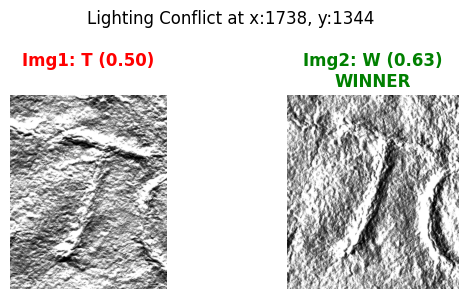

Conflict at roughly x:1350 y:1711 | Img1: 'S' (0.76) vs Img2: 'E' (0.34) --> Picked 'S'


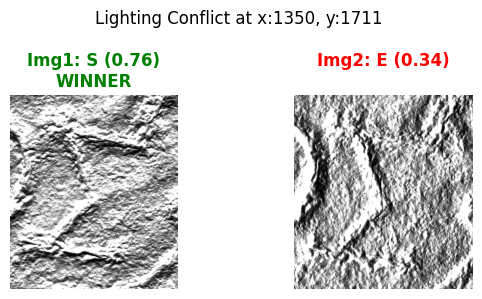

Conflict at roughly x:754 y:1583 | Img1: 'A' (0.74) vs Img2: 'S' (0.28) --> Picked 'A'


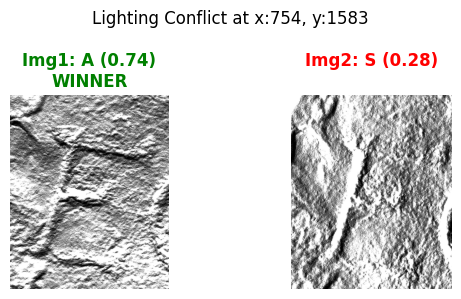

Conflict at roughly x:1621 y:1803 | Img1: 'R' (0.29) vs Img2: 'E' (0.22) --> Picked 'R'


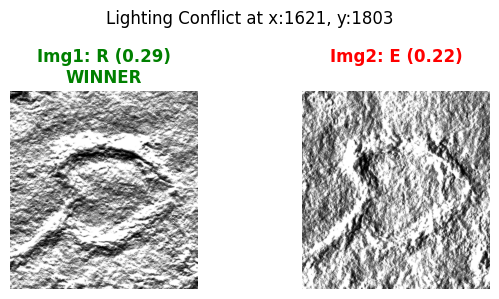

Conflict at roughly x:758 y:2009 | Img1: 'P' (0.49) vs Img2: 'T' (0.72) --> Picked 'T'


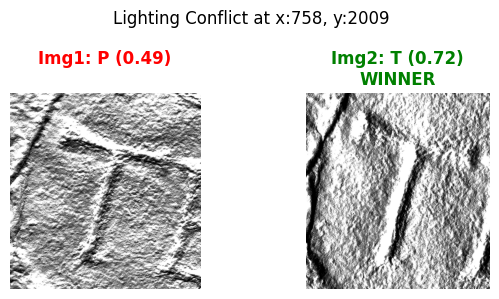

Conflict at roughly x:1174 y:2544 | Img1: 'O' (0.39) vs Img2: 'E' (0.17) --> Picked 'O'


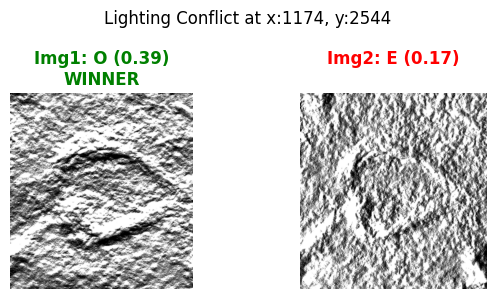

Conflict at roughly x:992 y:344 | Img1: 'S' (0.53) vs Img2: 'E' (0.51) --> Picked 'S'


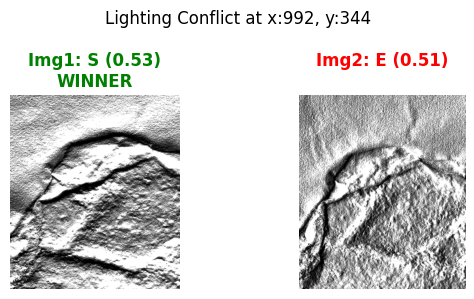

Conflict at roughly x:1254 y:409 | Img1: 'S' (0.50) vs Img2: 'D' (0.40) --> Picked 'S'


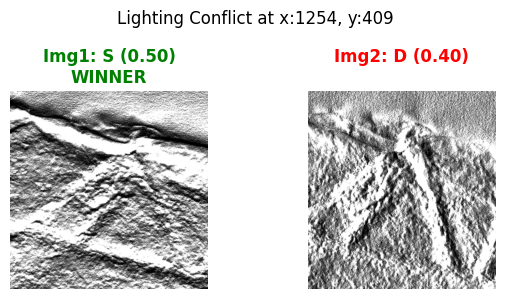

Conflict at roughly x:1901 y:531 | Img1: 'B' (0.41) vs Img2: 'A' (0.18) --> Picked 'B'


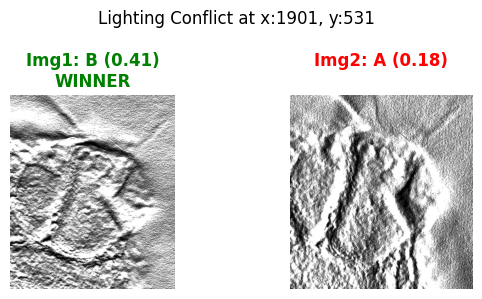

Conflict at roughly x:854 y:720 | Img1: 'G' (0.87) vs Img2: 'P' (0.25) --> Picked 'G'


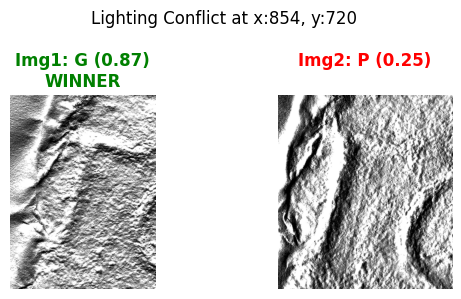

Conflict at roughly x:2227 y:1937 | Img1: 'F' (0.47) vs Img2: 'A' (0.15) --> Picked 'F'


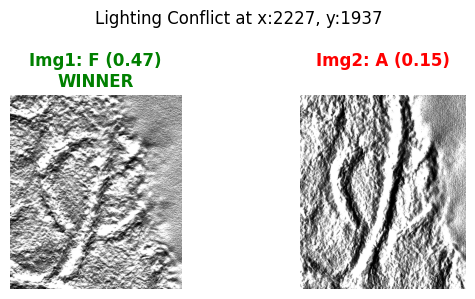

--------------------------------------------------
Tournament Complete. Total Disagreements Resolved: 11
Total letters classified: 34


In [5]:
import math
import matplotlib.pyplot as plt

# --- 1. RUN YOLO ON BOTH IMAGES SEPARATELY ---
print("Running Detection on Image 1...")
res1 = get_sliced_prediction(IMG1_PATH, detection_model, slice_height=640, slice_width=640, overlap_height_ratio=0.2, overlap_width_ratio=0.2, postprocess_type="NMS")
boxes1 = res1.object_prediction_list

print("Running Detection on Image 2...")
res2 = get_sliced_prediction(IMG2_PATH, detection_model, slice_height=640, slice_width=640, overlap_height_ratio=0.2, overlap_width_ratio=0.2, postprocess_type="NMS")
boxes2 = res2.object_prediction_list

# Load raw images
img1_cv2 = cv2.imread(IMG1_PATH)
img2_cv2 = cv2.imread(IMG2_PATH)
h1, w1, _ = img1_cv2.shape
h2, w2, _ = img2_cv2.shape

final_results = []
PROXIMITY_THRESHOLD = 50 # Max pixels they can be apart to be considered the same letter

print("-" * 50)
print("Running Proximity Matching & Classification Tournament...")

conflict_count = 0

# --- 2. MATCH AND COMPETE ---
for b1 in boxes1:
    # Get center of Box 1
    x1_min, y1_min, x1_max, y1_max = map(int, b1.bbox.to_xyxy())
    cx1, cy1 = (x1_min + x1_max) / 2, (y1_min + y1_max) / 2
    
    # Find the closest box in Image 2
    closest_b2 = None
    min_dist = float('inf')
    
    for b2 in boxes2:
        x2_min, y2_min, x2_max, y2_max = map(int, b2.bbox.to_xyxy())
        cx2, cy2 = (x2_min + x2_max) / 2, (y2_min + y2_max) / 2
        dist = math.hypot(cx1 - cx2, cy1 - cy2)
        
        if dist < min_dist:
            min_dist = dist
            closest_b2 = b2
            best_coords2 = (x2_min, y2_min, x2_max, y2_max)
            
    # If we found a matching box in Image 2 within our threshold
    if closest_b2 and min_dist < PROXIMITY_THRESHOLD:
        x2_min, y2_min, x2_max, y2_max = best_coords2
        
        # Safely Crop from Image 1
        x1_min_c, y1_min_c = max(0, x1_min), max(0, y1_min)
        x1_max_c, y1_max_c = min(w1, x1_max), min(h1, y1_max)
        crop1 = img1_cv2[y1_min_c:y1_max_c, x1_min_c:x1_max_c]
        
        # Safely Crop from Image 2
        x2_min_c, y2_min_c = max(0, x2_min), max(0, y2_min)
        x2_max_c, y2_max_c = min(w2, x2_max), min(h2, y2_max)
        crop2 = img2_cv2[y2_min_c:y2_max_c, x2_min_c:x2_max_c]
        
        if crop1.size == 0 or crop2.size == 0: continue
        
        # Preprocess
        t1 = cls_transforms(Image.fromarray(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
        t2 = cls_transforms(Image.fromarray(cv2.cvtColor(crop2, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
        
        # Predict
        with torch.no_grad():
            out1, out2 = classifier(t1), classifier(t2)
            conf1, p1 = torch.max(F.softmax(out1, dim=1), 1)
            conf2, p2 = torch.max(F.softmax(out2, dim=1), 1)
            
        label1, label2 = CLASS_NAMES[p1.item()], CLASS_NAMES[p2.item()]
        c1, c2 = conf1.item(), conf2.item()
        
        # Tournament Winner
        if c1 >= c2:
            best_label, best_conf = label1, c1
        else:
            best_label, best_conf = label2, c2
            
        # --- VISUAL VALIDATION OF CONFLICTS ---
        if label1 != label2:
            conflict_count += 1
            print(f"Conflict at roughly x:{int(cx1)} y:{int(cy1)} | Img1: '{label1}' ({c1:.2f}) vs Img2: '{label2}' ({c2:.2f}) --> Picked '{best_label}'")
            
            # Create a side-by-side plot
            fig, axes = plt.subplots(1, 2, figsize=(6, 3))
            
            axes[0].imshow(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))
            title1 = f"Img1: {label1} ({c1:.2f})\n{'WINNER' if c1 >= c2 else ''}"
            axes[0].set_title(title1, color='green' if c1 >= c2 else 'red', fontweight='bold')
            axes[0].axis('off')
            
            axes[1].imshow(cv2.cvtColor(crop2, cv2.COLOR_BGR2RGB))
            title2 = f"Img2: {label2} ({c2:.2f})\n{'WINNER' if c2 > c1 else ''}"
            axes[1].set_title(title2, color='green' if c2 > c1 else 'red', fontweight='bold')
            axes[1].axis('off')
            
            plt.suptitle(f"Lighting Conflict at x:{int(cx1)}, y:{int(cy1)}")
            plt.tight_layout()
            plt.show()
            
        # Store using Image 1's coordinates as the anchor (Saving full box for geometric reconstruction)
        final_results.append({
            'x1': x1_min, 'y1': y1_min, 
            'x2': x1_max, 'y2': y1_max, 
            'label': best_label, 'conf': best_conf
        })

    else:
        # YOLO only found it in Image 1! No tournament needed, just classify Crop 1.
        x1_min_c, y1_min_c = max(0, x1_min), max(0, y1_min)
        x1_max_c, y1_max_c = min(w1, x1_max), min(h1, y1_max)
        crop1 = img1_cv2[y1_min_c:y1_max_c, x1_min_c:x1_max_c]
        if crop1.size == 0: continue
        
        t1 = cls_transforms(Image.fromarray(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            conf1, p1 = torch.max(F.softmax(classifier(t1), dim=1), 1)
            
        final_results.append({
            'x1': x1_min, 'y1': y1_min, 
            'x2': x1_max, 'y2': y1_max, 
            'label': CLASS_NAMES[p1.item()], 'conf': conf1.item()
        })

print("-" * 50)
print(f"Tournament Complete. Total Disagreements Resolved: {conflict_count}")
print(f"Total letters classified: {len(final_results)}")

Running Detection on Image 1...
Performing prediction on 42 slices.
Running Detection on Image 2...
Performing prediction on 42 slices.
--------------------------------------------------
Running Proximity Matching & Logit Averaging Fusion...
Conflict at x:1738 y:1344 | Img1: 'T' (0.50) vs Img2: 'W' (0.63) --> FUSION Picked 'T' (0.25)


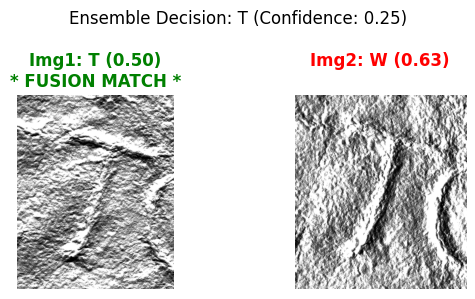

Conflict at x:1350 y:1711 | Img1: 'S' (0.76) vs Img2: 'E' (0.34) --> FUSION Picked 'S' (0.52)


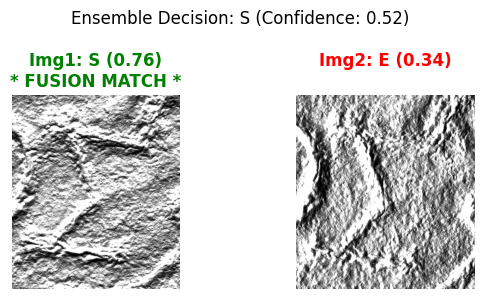

Conflict at x:754 y:1583 | Img1: 'A' (0.74) vs Img2: 'S' (0.28) --> FUSION Picked 'A' (0.63)


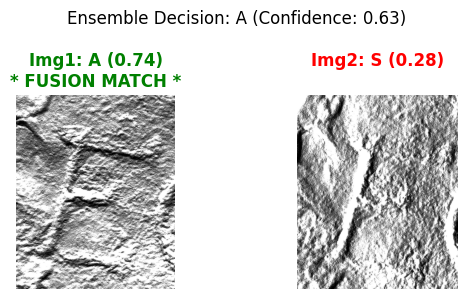

Conflict at x:1621 y:1803 | Img1: 'R' (0.29) vs Img2: 'E' (0.22) --> FUSION Picked 'O' (0.14)


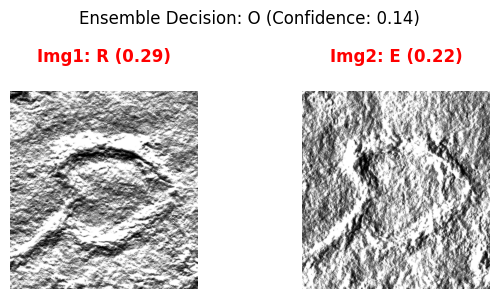

Conflict at x:758 y:2009 | Img1: 'P' (0.49) vs Img2: 'T' (0.72) --> FUSION Picked 'T' (0.66)


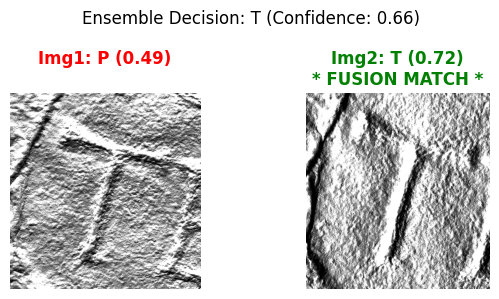

Conflict at x:1174 y:2544 | Img1: 'O' (0.39) vs Img2: 'E' (0.17) --> FUSION Picked 'E' (0.22)


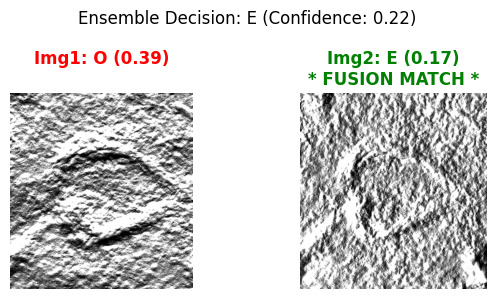

Conflict at x:992 y:344 | Img1: 'S' (0.53) vs Img2: 'E' (0.51) --> FUSION Picked 'E' (0.48)


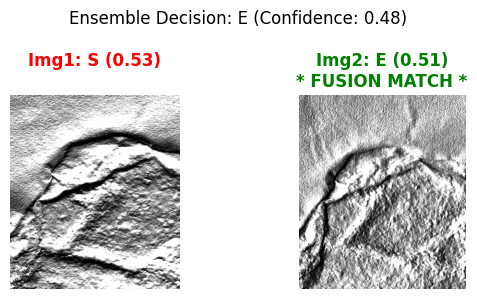

Conflict at x:1254 y:409 | Img1: 'S' (0.50) vs Img2: 'D' (0.40) --> FUSION Picked 'D' (0.45)


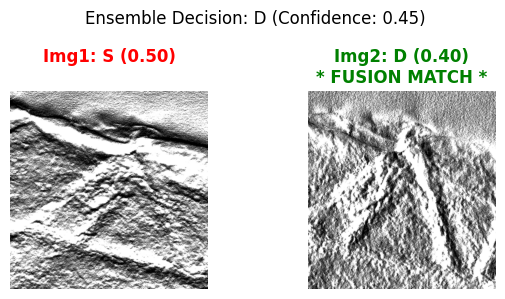

Conflict at x:1901 y:531 | Img1: 'B' (0.41) vs Img2: 'A' (0.18) --> FUSION Picked 'O' (0.19)


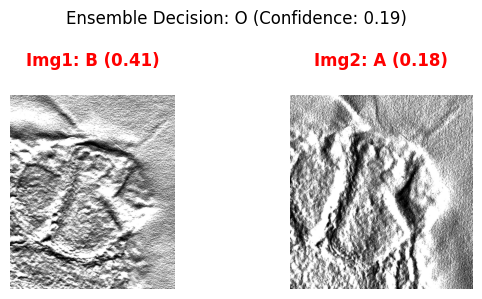

Conflict at x:854 y:720 | Img1: 'G' (0.87) vs Img2: 'P' (0.25) --> FUSION Picked 'G' (0.70)


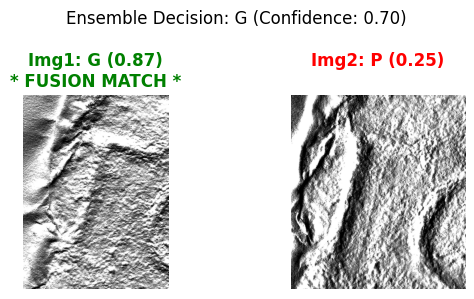

Conflict at x:2227 y:1937 | Img1: 'F' (0.47) vs Img2: 'A' (0.15) --> FUSION Picked 'A' (0.18)


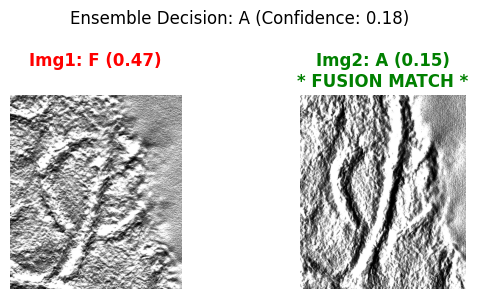

--------------------------------------------------
Fusion Complete. Total Disagreements Resolved: 11
Total letters classified: 34


In [6]:
import math
import matplotlib.pyplot as plt

# --- 1. RUN YOLO ON BOTH IMAGES SEPARATELY ---
print("Running Detection on Image 1...")
res1 = get_sliced_prediction(IMG1_PATH, detection_model, slice_height=640, slice_width=640, overlap_height_ratio=0.2, overlap_width_ratio=0.2, postprocess_type="NMS")
boxes1 = res1.object_prediction_list

print("Running Detection on Image 2...")
res2 = get_sliced_prediction(IMG2_PATH, detection_model, slice_height=640, slice_width=640, overlap_height_ratio=0.2, overlap_width_ratio=0.2, postprocess_type="NMS")
boxes2 = res2.object_prediction_list

# Load raw images
img1_cv2 = cv2.imread(IMG1_PATH)
img2_cv2 = cv2.imread(IMG2_PATH)
h1, w1, _ = img1_cv2.shape
h2, w2, _ = img2_cv2.shape

final_results = []
PROXIMITY_THRESHOLD = 50 # Max pixels they can be apart to be considered the same letter

print("-" * 50)
print("Running Proximity Matching & Logit Averaging Fusion...")

conflict_count = 0

# --- 2. MATCH AND COMPETE ---
for b1 in boxes1:
    # Get center of Box 1
    x1_min, y1_min, x1_max, y1_max = map(int, b1.bbox.to_xyxy())
    cx1, cy1 = (x1_min + x1_max) / 2, (y1_min + y1_max) / 2
    
    # Find the closest box in Image 2
    closest_b2 = None
    min_dist = float('inf')
    
    for b2 in boxes2:
        x2_min, y2_min, x2_max, y2_max = map(int, b2.bbox.to_xyxy())
        cx2, cy2 = (x2_min + x2_max) / 2, (y2_min + y2_max) / 2
        dist = math.hypot(cx1 - cx2, cy1 - cy2)
        
        if dist < min_dist:
            min_dist = dist
            closest_b2 = b2
            best_coords2 = (x2_min, y2_min, x2_max, y2_max)
            
    # If we found a matching box in Image 2 within our threshold
    if closest_b2 and min_dist < PROXIMITY_THRESHOLD:
        x2_min, y2_min, x2_max, y2_max = best_coords2
        
        # Safely Crop from Image 1
        x1_min_c, y1_min_c = max(0, x1_min), max(0, y1_min)
        x1_max_c, y1_max_c = min(w1, x1_max), min(h1, y1_max)
        crop1 = img1_cv2[y1_min_c:y1_max_c, x1_min_c:x1_max_c]
        
        # Safely Crop from Image 2
        x2_min_c, y2_min_c = max(0, x2_min), max(0, y2_min)
        x2_max_c, y2_max_c = min(w2, x2_max), min(h2, y2_max)
        crop2 = img2_cv2[y2_min_c:y2_max_c, x2_min_c:x2_max_c]
        
        if crop1.size == 0 or crop2.size == 0: continue
        
        # Preprocess
        t1 = cls_transforms(Image.fromarray(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
        t2 = cls_transforms(Image.fromarray(cv2.cvtColor(crop2, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
        
        # --- THE LATE FUSION (LOGIT AVERAGING) ---
        with torch.no_grad():
            out1, out2 = classifier(t1), classifier(t2)
            
            # We still calculate individual confidences just so we can print them in the graphs
            conf1, p1 = torch.max(F.softmax(out1, dim=1), 1)
            conf2, p2 = torch.max(F.softmax(out2, dim=1), 1)
            label1, label2 = CLASS_NAMES[p1.item()], CLASS_NAMES[p2.item()]
            c1, c2 = conf1.item(), conf2.item()
            
            # THE ACTUAL FUSION MATH: Average the raw logits BEFORE softmax
            avg_logits = (out1 + out2) / 2.0
            
            # Now apply softmax to the combined evidence to get the final fused prediction
            avg_probs = F.softmax(avg_logits, dim=1)
            best_conf_tensor, best_p_tensor = torch.max(avg_probs, 1)
            
            best_label = CLASS_NAMES[best_p_tensor.item()]
            best_conf = best_conf_tensor.item()
            
        # --- VISUAL VALIDATION OF CONFLICTS ---
        if label1 != label2:
            conflict_count += 1
            print(f"Conflict at x:{int(cx1)} y:{int(cy1)} | Img1: '{label1}' ({c1:.2f}) vs Img2: '{label2}' ({c2:.2f}) --> FUSION Picked '{best_label}' ({best_conf:.2f})")
            
            # Create a side-by-side plot
            fig, axes = plt.subplots(1, 2, figsize=(6, 3))
            
            axes[0].imshow(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))
            title1 = f"Img1: {label1} ({c1:.2f})\n{'* FUSION MATCH *' if best_label == label1 else ''}"
            axes[0].set_title(title1, color='green' if best_label == label1 else 'red', fontweight='bold')
            axes[0].axis('off')
            
            axes[1].imshow(cv2.cvtColor(crop2, cv2.COLOR_BGR2RGB))
            title2 = f"Img2: {label2} ({c2:.2f})\n{'* FUSION MATCH *' if best_label == label2 else ''}"
            axes[1].set_title(title2, color='green' if best_label == label2 else 'red', fontweight='bold')
            axes[1].axis('off')
            
            plt.suptitle(f"Ensemble Decision: {best_label} (Confidence: {best_conf:.2f})")
            plt.tight_layout()
            plt.show()
            
        # Store using Image 1's coordinates as the anchor (Saving full box for geometric reconstruction)
        final_results.append({
            'x1': x1_min, 'y1': y1_min, 
            'x2': x1_max, 'y2': y1_max, 
            'label': best_label, 'conf': best_conf
        })

    else:
        # YOLO only found it in Image 1! No fusion needed, just classify Crop 1.
        x1_min_c, y1_min_c = max(0, x1_min), max(0, y1_min)
        x1_max_c, y1_max_c = min(w1, x1_max), min(h1, y1_max)
        crop1 = img1_cv2[y1_min_c:y1_max_c, x1_min_c:x1_max_c]
        if crop1.size == 0: continue
        
        t1 = cls_transforms(Image.fromarray(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            conf1, p1 = torch.max(F.softmax(classifier(t1), dim=1), 1)
            
        final_results.append({
            'x1': x1_min, 'y1': y1_min, 
            'x2': x1_max, 'y2': y1_max, 
            'label': CLASS_NAMES[p1.item()], 'conf': conf1.item()
        })

print("-" * 50)
print(f"Fusion Complete. Total Disagreements Resolved: {conflict_count}")
print(f"Total letters classified: {len(final_results)}")

In [7]:
import math

def calculate_row_bbox(row_boxes):
    """Calculates the enclosing bounding box for a list of character boxes."""
    x1 = min(b['x1'] for b in row_boxes)
    y1 = min(b['y1'] for b in row_boxes)
    x2 = max(b['x2'] for b in row_boxes)
    y2 = max(b['y2'] for b in row_boxes)
    return x1, y1, x2, y2

def calculate_ioa(row1, row2):
    """
    Calculates the Intersection-over-Area (IoA) for two candidate rows
    to determine if they should be merged.
    """
    r1_x1, r1_y1, r1_x2, r1_y2 = calculate_row_bbox(row1)
    r2_x1, r2_y1, r2_x2, r2_y2 = calculate_row_bbox(row2)
    
    area1 = max(0, r1_x2 - r1_x1) * max(0, r1_y2 - r1_y1)
    area2 = max(0, r2_x2 - r2_x1) * max(0, r2_y2 - r2_y1)
    
    if area1 == 0 or area2 == 0: 
        return 0, 0
        
    # Intersection coordinates
    ix1, iy1 = max(r1_x1, r2_x1), max(r1_y1, r2_y1)
    ix2, iy2 = min(r1_x2, r2_x2), min(r1_y2, r2_y2)
    
    inter_area = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    
    # Return IoA relative to both rows
    return inter_area / area1, inter_area / area2


def generate_transcript_from_paper(results):
    if not results: return ""
        
    # --- PHASE 1: COMPUTE GEOMETRY & RADII ---
    for i, box in enumerate(results):
        box['id'] = i
        box['cx'] = (box['x1'] + box['x2']) / 2.0
        box['cy'] = (box['y1'] + box['y2']) / 2.0
        
        w = box['x2'] - box['x1']
        h = box['y2'] - box['y1']
        # r(Bj) is defined as half the length of a diagonal of Bj
        box['r'] = 0.5 * math.hypot(w, h)
        
    # --- PHASE 2: FIND HORIZONTAL NEIGHBORS ---
    for i, box_i in enumerate(results):
        left_neighbors = []
        right_neighbors = []
        
        for j, box_j in enumerate(results):
            if i == j: continue
            
            # Condition: Center of Bj is within r(Bj) of the horizontal line passing through Bi
            if abs(box_j['cy'] - box_i['cy']) <= box_j['r']:
                if box_j['cx'] < box_i['cx']:
                    left_neighbors.append(box_j)
                elif box_j['cx'] > box_i['cx']:
                    right_neighbors.append(box_j)
                    
        # Find closest left (max X) and closest right (min X)
        box_i['left'] = max(left_neighbors, key=lambda b: b['cx'])['id'] if left_neighbors else None
        box_i['right'] = min(right_neighbors, key=lambda b: b['cx'])['id'] if right_neighbors else None

    # --- PHASE 3: GREEDY ROW CONSTRUCTION ---
    unassociated = set(range(len(results)))
    candidate_rows = []
    
    while unassociated:
        # Pick an arbitrary unassigned seed box
        seed_id = unassociated.pop()
        current_row = [seed_id]
        
        # Expand Left
        curr_id = seed_id
        while True:
            left_id = results[curr_id]['left']
            if left_id is not None and left_id in unassociated:
                current_row.insert(0, left_id)
                unassociated.remove(left_id)
                curr_id = left_id
            else: 
                break
                
        # Expand Right
        curr_id = seed_id
        while True:
            right_id = results[curr_id]['right']
            if right_id is not None and right_id in unassociated:
                current_row.append(right_id)
                unassociated.remove(right_id)
                curr_id = right_id
            else: 
                break
                
        candidate_rows.append([results[i] for i in current_row])
        
    # --- PHASE 4: MERGE OVERLAPS (IoA HEURISTIC) ---
    merged = True
    while merged:
        merged = False
        new_rows = []
        skip = set()
        
        for i in range(len(candidate_rows)):
            if i in skip: continue
            
            merged_row = candidate_rows[i]
            for j in range(i + 1, len(candidate_rows)):
                if j in skip: continue
                
                ioa1, ioa2 = calculate_ioa(merged_row, candidate_rows[j])
                
                # Rule: mutual IoA > 50% OR one-way IoA > 80%
                if (ioa1 > 0.5 and ioa2 > 0.5) or ioa1 > 0.8 or ioa2 > 0.8:
                    merged_row.extend(candidate_rows[j])
                    skip.add(j)
                    merged = True
                    
            new_rows.append(merged_row)
        candidate_rows = new_rows

    # --- PHASE 5: FINAL SORTING & STRING ASSEMBLY ---
    # Sort boxes within each row from left to right (by center X)
    for row in candidate_rows:
        row.sort(key=lambda b: b['cx']) 
        
    # Sort the rows themselves top to bottom based on average Y position
    candidate_rows.sort(key=lambda row: sum(b['cy'] for b in row) / len(row)) 
    
    # Build final string
    transcript_lines = []
    for row in candidate_rows:
        transcript_lines.append("".join([b['label'] for b in row]))
        
    return "\n".join(transcript_lines)

# Generate and print the final transcript
print("-" * 50)
print("FINAL RECONSTRUCTED TRANSCRIPT:")
print("-" * 50)
final_transcript = generate_transcript_from_paper(final_results)
print(final_transcript)
print("-" * 50)

--------------------------------------------------
FINAL RECONSTRUCTED TRANSCRIPT:
--------------------------------------------------
EDM
AO
GOYY
OYSTO
AOSOSA
YTESTASM
YSEWNP
--------------------------------------------------


In [6]:
# def align_images(img1_path, img2_path):
#     print("Aligning Image 2 to Image 1...")
#     img1 = cv2.imread(img1_path)
#     img2 = cv2.imread(img2_path)
    
#     gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
#     gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

#     sift = cv2.SIFT_create()
#     kp1, des1 = sift.detectAndCompute(gray1, None)
#     kp2, des2 = sift.detectAndCompute(gray2, None)

#     flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))
#     matches = flann.knnMatch(des1, des2, k=2)

#     good_matches = [m for m, n in matches if m.distance < 0.7 * n.distance]

#     points1 = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
#     points2 = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

#     # Calculate Homography and warp Image 2
#     h_matrix, _ = cv2.findHomography(points2, points1, cv2.RANSAC)
#     height, width = gray1.shape
#     img2_aligned = cv2.warpPerspective(img2, h_matrix, (width, height))
    
#     print("Alignment complete.")
#     return img1, img2_aligned

# img1_cv2, img2_aligned_cv2 = align_images(IMG1_PATH, IMG2_PATH)

# # Optional: Visualize to ensure they match
# plt.imshow(cv2.cvtColor(img2_aligned_cv2, cv2.COLOR_BGR2RGB)); plt.show()

In [7]:
# print("Running SAHI Inference on Image 1...")
# result = get_sliced_prediction(
#     IMG1_PATH,
#     detection_model,
#     slice_height=640,
#     slice_width=640,
#     overlap_height_ratio=0.2,
#     overlap_width_ratio=0.2,
#     postprocess_type="NMS",
# )

# master_boxes = result.object_prediction_list
# print(f"Found {len(master_boxes)} total text boxes.")

In [11]:
final_results = []
h_img, w_img, _ = img1_cv2.shape

print("Running Classification Tournament...")
print("-" * 50)

# Counters for our logs
conflict_count = 0
img1_wins = 0
img2_wins = 0

for pred in master_boxes:
    # 1. Get Coordinates
    x1, y1, x2, y2 = map(int, pred.bbox.to_xyxy())
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w_img, x2), min(h_img, y2)
    
    # 2. Crop from BOTH images
    crop1 = img1_cv2[y1:y2, x1:x2]
    crop2 = img2_aligned_cv2[y1:y2, x1:x2]
    
    if crop1.size == 0 or crop2.size == 0: continue

    # 3. Preprocess both
    t1 = cls_transforms(Image.fromarray(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
    t2 = cls_transforms(Image.fromarray(cv2.cvtColor(crop2, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
    
    # 4. Predict & Compare Softmax Confidence
    with torch.no_grad():
        out1 = classifier(t1)
        out2 = classifier(t2)
        
        prob1 = F.softmax(out1, dim=1)
        prob2 = F.softmax(out2, dim=1)
        
        conf1, p1 = torch.max(prob1, 1)
        conf2, p2 = torch.max(prob2, 1)
        
    # Extract labels and confidences for easier reading
    label1 = CLASS_NAMES[p1.item()]
    label2 = CLASS_NAMES[p2.item()]
    c1 = conf1.item()
    c2 = conf2.item()
        
    # 5. The Winner takes it all
    if c1 >= c2:
        best_label = label1
        best_conf = c1
        winner = "Image 1"
        if label1 != label2: img1_wins += 1
    else:
        best_label = label2
        best_conf = c2
        winner = "Image 2"
        if label1 != label2: img2_wins += 1
        
    # 6. LOGGING THE CONFLICTS
    if label1 != label2:
        conflict_count += 1
        print(f"Conflict at x:{int(x1)} y:{int(y1)} | "
              f"Img1: '{label1}' ({c1:.2f}) vs Img2: '{label2}' ({c2:.2f}) "
              f"--> Picked '{best_label}' from {winner}")
        
    final_results.append({
        'x': (x1 + x2) / 2, 
        'y': (y1 + y2) / 2, 
        'label': best_label,
        'conf': best_conf
    })

print("-" * 50)
print(f"Classified {len(final_results)} letters successfully.")
print(f"Total Disagreements Resolved: {conflict_count}")
if conflict_count > 0:
    print(f"Image 1 won {img1_wins} times | Image 2 won {img2_wins} times")
print("-" * 50)

Running Classification Tournament...
--------------------------------------------------


NameError: name 'master_boxes' is not defined

In [ ]:
# final_results = []
# h_img, w_img, _ = img1_cv2.shape

# print("Running Classification Tournament...")
# for pred in master_boxes:
#     # 1. Get Coordinates
#     x1, y1, x2, y2 = map(int, pred.bbox.to_xyxy())
#     x1, y1 = max(0, x1), max(0, y1)
#     x2, y2 = min(w_img, x2), min(h_img, y2)
    
#     # 2. Crop from BOTH images
#     crop1 = img1_cv2[y1:y2, x1:x2]
#     crop2 = img2_aligned_cv2[y1:y2, x1:x2]
    
#     if crop1.size == 0 or crop2.size == 0: continue

#     # 3. Preprocess both
#     t1 = cls_transforms(Image.fromarray(cv2.cvtColor(crop1, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
#     t2 = cls_transforms(Image.fromarray(cv2.cvtColor(crop2, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
    
#     # 4. Predict & Compare Softmax Confidence
#     with torch.no_grad():
#         out1 = classifier(t1)
#         out2 = classifier(t2)
        
#         prob1 = F.softmax(out1, dim=1)
#         prob2 = F.softmax(out2, dim=1)
        
#         conf1, p1 = torch.max(prob1, 1)
#         conf2, p2 = torch.max(prob2, 1)
        
#     # 5. The Winner takes it all
#     if conf1.item() >= conf2.item():
#         best_label = CLASS_NAMES[p1.item()]
#         best_conf = conf1.item()
#     else:
#         best_label = CLASS_NAMES[p2.item()]
#         best_conf = conf2.item()
        
#     final_results.append({
#         'x': (x1 + x2) / 2, 
#         'y': (y1 + y2) / 2, 
#         'label': best_label,
#         'conf': best_conf
#     })

# print(f"Classified {len(final_results)} letters successfully.")

In [12]:
def reconstruct_transcript(results, line_threshold=350):
    if not results: return ""

    # Sort by Y to roughly establish lines
    results.sort(key=lambda k: k['y'])
    
    lines = []
    current_line = []
    current_y_avg = results[0]['y']
    
    for item in results:
        if abs(item['y'] - current_y_avg) < line_threshold:
            current_line.append(item)
            current_y_avg = sum(c['y'] for c in current_line) / len(current_line)
        else:
            # Sort the finished line by X (Left to Right)
            current_line.sort(key=lambda k: k['x'])
            lines.append(current_line)
            current_line = [item]
            current_y_avg = item['y']
            
    if current_line:
        current_line.sort(key=lambda k: k['x'])
        lines.append(current_line)

    full_transcript = []
    for line in lines:
        full_transcript.append("".join([item['label'] for item in line]))
        
    return "\n".join(full_transcript)

# Generate and print
transcript = reconstruct_transcript(final_results)
print("\n" + "="*30)
print("FINAL TRANSCRIPT:")
print("="*30)
print(transcript)
print("="*30)


FINAL TRANSCRIPT:



In [8]:
import matplotlib.pyplot as plt

def visualize_predictions(image_cv2, results):
    """
    Draws the predicted labels directly onto the image.
    """
    # Create a copy to draw on
    vis_img = image_cv2.copy()
    
    # Constants for drawing
    FONT = cv2.FONT_HERSHEY_SIMPLEX
    FONT_SCALE = 0.7
    FONT_COLOR = (0, 255, 0) # Neon Green
    THICKNESS = 2
    BG_COLOR = (0, 0, 0) # Black background box for readability

    print(f"Drawing {len(results)} labels on the image...")

    for item in results:
        label = item['label']
        x = int(item['x'])
        y = int(item['y'])
        
        # 1. Get text size to draw a background box
        (text_w, text_h), baseline = cv2.getTextSize(label, FONT, FONT_SCALE, THICKNESS)
        
        # Center the text over the prediction point
        text_x = x - (text_w // 2)
        text_y = y + (text_h // 2)

        # 2. Draw filled rectangle (background)
        cv2.rectangle(vis_img, 
                      (text_x - 2, text_y - text_h - 2), 
                      (text_x + text_w + 2, text_y + baseline + 2), 
                      BG_COLOR, 
                      cv2.FILLED)
        
        # 3. Draw the text label
        cv2.putText(vis_img, 
                    label, 
                    (text_x, text_y), 
                    FONT, 
                    FONT_SCALE, 
                    FONT_COLOR, 
                    THICKNESS)

    # Convert BGR to RGB for Matplotlib display
    vis_img_rgb = cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB)
    
    # Plot
    plt.figure(figsize=(20, 20)) # Large size for detailed viewing
    plt.imshow(vis_img_rgb)
    plt.axis('off')
    plt.title("Final Transcribed Image (Visual Validation)")
    plt.show()

# Run the visualization
visualize_predictions(img1_cv2, final_results)

Drawing 34 labels on the image...


KeyError: 'x'